# IEEE 37-bus modified one-shot DDPG reward matrix

## Purpose

This notebook trains, evaluates, or views one-shot DDPG runs under the `band` reward with an added deviation term. The matrix compares three cells: `abs` alpha `0.1`, `sq` alpha `0.001`, and `exp` alpha `1e-05`. The `alpha = 0` control comes from `os_random_ddpg.ipynb` and is only read here. Results describe this saved validation split and synthetic process only.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().parents[1]
if not (ROOT / "src/feeder").is_dir():
    raise RuntimeError("Start the kernel in the notebook directory (experiments/<feeder>/).")
sys.path.insert(0, str(ROOT / "src"))

from common.reports import show_reward_matrix, show_reward_matrix_conclusions, show_reward_matrix_training
from common.workflow import run_experiment_matrix

print("Repository root resolved.")

Repository root resolved.


## Parameters

Edit this cell, then restart the kernel and run all cells. `MODE` selects `train`, `evaluate`, or read-only `view` for the three cells; `OVERWRITE` affects only writing modes. The control always runs in `view` mode.

In [2]:
FEEDER = "ieee37mod"  # Named feeder.
DATASET = "ieee37mod-random"  # Named dataset.
SEEDS = [0, 1, 2]  # Independent training seeds.
MODE = "view"  # train, evaluate, or read saved results.
OVERWRITE = False  # Applies only to train and evaluate.
EPISODES = 20000  # Training only: interactions per run.
SPLIT = "validation"  # Evaluation split.
EVALUATION_DAYS = None  # Complete split or a positive day limit.
RATE = 20.0  # Exponent rate of the exp deviation.
CONTROL_RUN_NAME = "band"  # Control run name before _seed<seed>.
CELLS = [  # Deviation kind, alpha, run name before _seed<seed>.
    ("abs", 0.1, "band_abs_a0.1"),
    ("sq", 0.001, "band_sq_a0.001"),
    ("exp", 0.00001, "band_exp_a1e-05"),
]


**Units and interfaces.** Each run's reward adds `alpha` times the mean deviation of `|v - 1|` to the band cost. Reported voltage cost and mean absolute deviation are fixed metrics that do not depend on the training reward.

In [3]:
BASE = {
    "protocol": "one_shot",
    "algorithm": "ddpg",
    "feeder": FEEDER,
    "dataset": DATASET,
    "seeds": SEEDS,
    "mode": MODE,
    "overwrite": OVERWRITE,
    "episodes": EPISODES,
    "split": SPLIT,
    "evaluation_days": EVALUATION_DAYS,
    "reward": "band",
    "run_name": CONTROL_RUN_NAME,
    "root": ROOT,
}
control, cells = run_experiment_matrix(BASE, CELLS, rate=RATE)

Cell band: reward band {'beta': 0.0, 'deviation': 'abs', 'alpha': 0.0, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}; runs results/ieee37mod-random/ddpg/band_seed0/, results/ieee37mod-random/ddpg/band_seed1/, results/ieee37mod-random/ddpg/band_seed2/
Preflight passed. No subprocess has started before this point.
Using existing saved results. View mode launches no subprocess.
Scenario alignment passed for 4800 hours and 5 methods.
Cell band_abs_a0.1: reward band {'beta': 0.0, 'deviation': 'abs', 'alpha': 0.1, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}; runs results/ieee37mod-random/ddpg/band_abs_a0.1_seed0/, results/ieee37mod-random/ddpg/band_abs_a0.1_seed1/, results/ieee37mod-random/ddpg/band_abs_a0.1_seed2/
Preflight passed. No subprocess has started before this point.
Using existing saved results. View mode launches no subprocess.


Scenario alignment passed for 4800 hours and 5 methods.


Cell band_sq_a0.001: reward band {'beta': 0.0, 'deviation': 'sq', 'alpha': 0.001, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}; runs results/ieee37mod-random/ddpg/band_sq_a0.001_seed0/, results/ieee37mod-random/ddpg/band_sq_a0.001_seed1/, results/ieee37mod-random/ddpg/band_sq_a0.001_seed2/
Preflight passed. No subprocess has started before this point.
Using existing saved results. View mode launches no subprocess.
Scenario alignment passed for 4800 hours and 5 methods.
Cell band_exp_a1e-05: reward band {'beta': 0.0, 'deviation': 'exp', 'alpha': 1e-05, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}; runs results/ieee37mod-random/ddpg/band_exp_a1e-05_seed0/, results/ieee37mod-random/ddpg/band_exp_a1e-05_seed1/, results/ieee37mod-random/ddpg/band_exp_a1e-05_seed2/


Preflight passed. No subprocess has started before this point.
Using existing saved results. View mode launches no subprocess.


Scenario alignment passed for 4800 hours and 5 methods.


## Training records

These records cover the three cells and the `alpha = 0` baseline. “Training voltage cost per scenario” uses one physical cost definition across cells. Each curve averages the selected seeds before smoothing.

Cost uses the fixed evaluation metric on training episodes and includes exploration. These curves are not held-out performance or proof of convergence.

Run,Reward,Reward parameters,Benchmark beta,Layer sizes,Completed training episodes,Update counts
DDPG seed 0,band,"{'beta': 0.0, 'deviation': 'abs', 'alpha': 0.1, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",None,"[400, 300]",20000,unavailable
DDPG seed 1,band,"{'beta': 0.0, 'deviation': 'abs', 'alpha': 0.1, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",None,"[400, 300]",20000,unavailable
DDPG seed 2,band,"{'beta': 0.0, 'deviation': 'abs', 'alpha': 0.1, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",None,"[400, 300]",20000,unavailable


Run,Reward,Reward parameters,Benchmark beta,Layer sizes,Completed training episodes,Update counts
DDPG seed 0,band,"{'beta': 0.0, 'deviation': 'sq', 'alpha': 0.001, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",None,"[400, 300]",20000,unavailable
DDPG seed 1,band,"{'beta': 0.0, 'deviation': 'sq', 'alpha': 0.001, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",None,"[400, 300]",20000,unavailable
DDPG seed 2,band,"{'beta': 0.0, 'deviation': 'sq', 'alpha': 0.001, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",None,"[400, 300]",20000,unavailable


Run,Reward,Reward parameters,Benchmark beta,Layer sizes,Completed training episodes,Update counts
DDPG seed 0,band,"{'beta': 0.0, 'deviation': 'exp', 'alpha': 1e-05, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",None,"[400, 300]",20000,unavailable
DDPG seed 1,band,"{'beta': 0.0, 'deviation': 'exp', 'alpha': 1e-05, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",None,"[400, 300]",20000,unavailable
DDPG seed 2,band,"{'beta': 0.0, 'deviation': 'exp', 'alpha': 1e-05, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",None,"[400, 300]",20000,unavailable


Run,Reward,Reward parameters,Benchmark beta,Layer sizes,Completed training episodes,Update counts
DDPG seed 0,band,"{'beta': 0.0, 'deviation': 'abs', 'alpha': 0.0, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",None,"[400, 300]",20000,unavailable
DDPG seed 1,band,"{'beta': 0.0, 'deviation': 'abs', 'alpha': 0.0, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",None,"[400, 300]",20000,unavailable
DDPG seed 2,band,"{'beta': 0.0, 'deviation': 'abs', 'alpha': 0.0, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",None,"[400, 300]",20000,unavailable


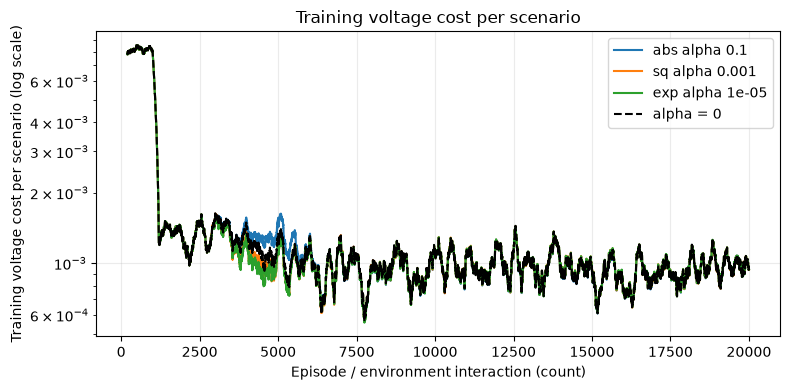

Cost uses the fixed evaluation metric on training episodes and includes exploration. It is not held-out performance or proof of convergence.

In [4]:
show_reward_matrix_training(cells, control);

## Reward matrix

Each cell is a seed mean ± sample standard deviation of per-run metrics. Paired differences match seeds and inputs; spread across three seeds is not a confidence interval.

Cell,Mean hourly voltage cost
abs alpha 0.1,1.500e-04 ± 1.894e-06
sq alpha 0.001,1.388e-04 ± 1.052e-06
exp alpha 1e-05,1.399e-04 ± 2.996e-06
alpha = 0,1.428e-04 ± 3.489e-06


Cell,Mean absolute deviation (p.u.)
abs alpha 0.1,2.5710e-02 ± 3.4630e-04
sq alpha 0.001,2.9175e-02 ± 1.1701e-03
exp alpha 1e-05,3.1108e-02 ± 1.6018e-03
alpha = 0,3.0102e-02 ± 2.2688e-03


Cell,Feasible scenarios (%)
abs alpha 0.1,7.8 ± 6.8
sq alpha 0.001,16.5 ± 1.3
exp alpha 1e-05,9.7 ± 8.4
alpha = 0,16.6 ± 1.5


Cell,Mean violating voltage measurements/scenario
abs alpha 0.1,22.08 ± 1.49
sq alpha 0.001,22.14 ± 1.50
exp alpha 1e-05,22.73 ± 1.90
alpha = 0,23.87 ± 1.53


Cell,Mean hourly voltage cost
abs alpha 0.1,7.212e-06 ± 4.371e-06
sq alpha 0.001,-4.008e-06 ± 2.728e-06
exp alpha 1e-05,-2.829e-06 ± 5.820e-06


Cell,Mean absolute deviation (p.u.)
abs alpha 0.1,-4.3912e-03 ± 1.9322e-03
sq alpha 0.001,-9.2665e-04 ± 2.7660e-03
exp alpha 1e-05,1.0064e-03 ± 3.1676e-03


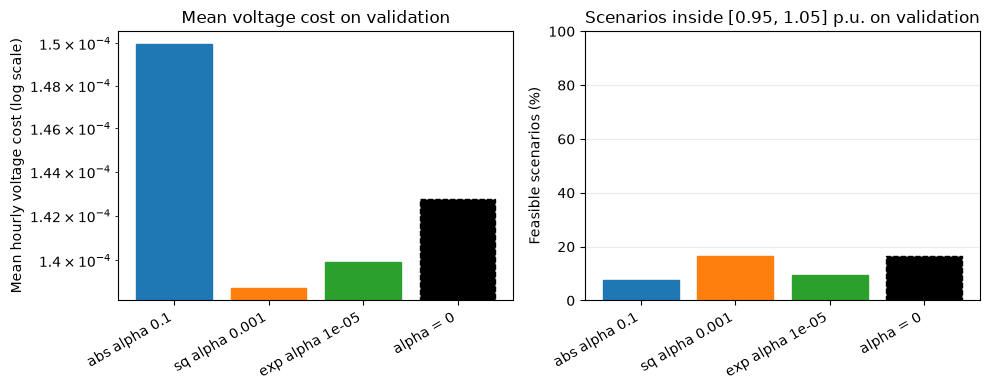

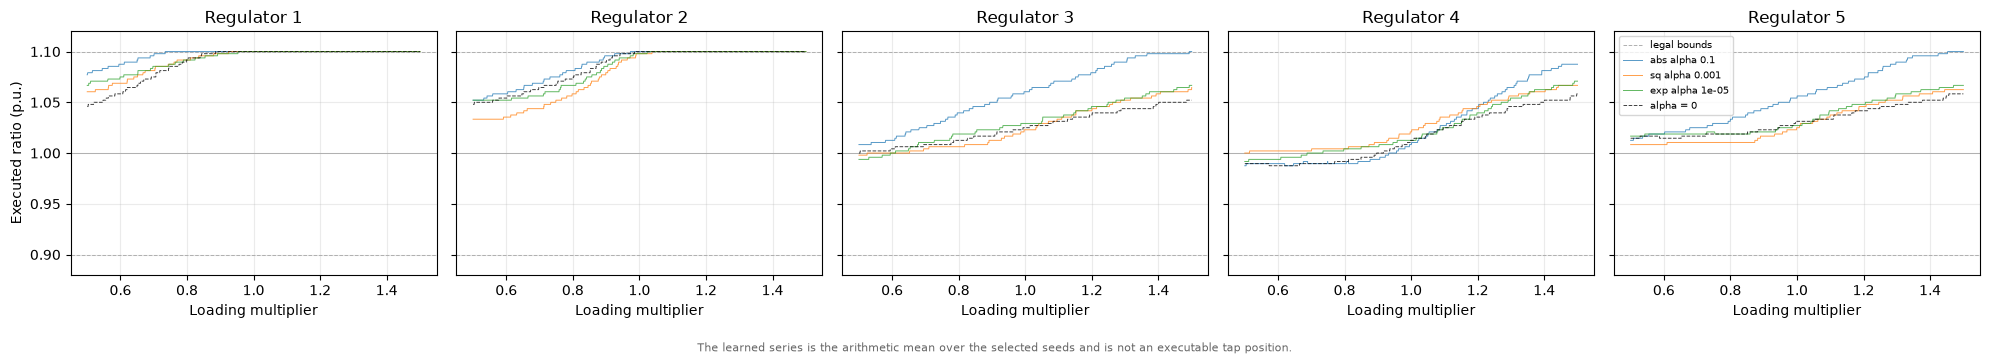

The learned series is the arithmetic mean over the selected seeds and is not an executable tap position.

In [5]:
show_reward_matrix(cells, control, include_training=False);

## Final answers

In [6]:
show_reward_matrix_conclusions(cells, control)

Mean hourly voltage cost: the alpha = 0 control has seed mean 1.428e-04; the lowest seed mean is 1.388e-04 for deviation sq, alpha 0.001.

Mean absolute deviation (p.u.): the alpha = 0 control has seed mean 3.0102e-02; the lowest seed mean is 2.5710e-02 for deviation abs, alpha 0.1.

Feasible scenarios (%): the alpha = 0 control has seed mean 16.6; the highest seed mean is 16.5 for deviation sq, alpha 0.001.

Mean violating voltage measurements/scenario: the alpha = 0 control has seed mean 23.87; the lowest seed mean is 22.08 for deviation abs, alpha 0.1.

1 of 3 cells have a mean hourly voltage cost below the control on all 3 seeds.

These statements describe the saved validation split and these dataset inputs only.